# So sánh Batch, Stochastic và Mini-batch Gradient Descent (mục 5.2)

(a) quỹ đạo 60 lần cập nhật đầu tiên trên đường đồng mức, (b) hàm mất mát theo epoch

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

1000 điểm gần đường thẳng y = 4 + 3x

In [2]:
np.random.seed(2)
X = np.random.rand(1000)
y = 4 + 3 * X + .2 * np.random.randn(1000)
Xbar = np.column_stack([np.ones(len(X)), X])
w_ols = np.linalg.pinv(Xbar.T @ Xbar) @ Xbar.T @ y

def cost(w):
    """Hàm mất mát L(w) trên toàn bộ dữ liệu."""
    return .5 / len(y) * np.sum((Xbar @ w - y)**2)

def minibatch_gd(eta, batch_size, n_epochs, seed=0):
    """Mini-batch GD; batch_size = N là Batch GD, batch_size = 1 là SGD."""
    rng = np.random.default_rng(seed)
    w = np.array([2., 1.])
    w_history, losses = [w], [cost(w)]
    N = len(y)
    for _ in range(n_epochs):
        idx = rng.permutation(N)              # xáo trộn dữ liệu mỗi epoch
        for s in range(0, N, batch_size):
            b = idx[s:s + batch_size]         # chỉ số các mẫu trong một mini-batch
            w = w - eta * Xbar[b].T @ (Xbar[b] @ w - y[b]) / len(b)
            w_history.append(w)
        losses.append(cost(w))
    return np.array(w_history), losses

(tên, kích thước batch, tốc độ học η, màu)

In [3]:
configs = [("Batch GD ($\\eta$ = 1)", 1000, 1.0, "#1F77B4"),
            ("Stochastic GD ($\\eta$ = 0.05)", 1, 0.05, "#D62728"),
            ("Mini-batch GD, m = 32 ($\\eta$ = 0.5)", 32, 0.5, "#2CA02C")]

W0, W1 = np.meshgrid(np.linspace(1.5, 5, 200), np.linspace(0.5, 4, 200))
L = np.array([[cost(np.array([a, b])) for a, b in zip(r0, r1)] for r0, r1 in zip(W0, W1)])

Vẽ hình và lưu ảnh.

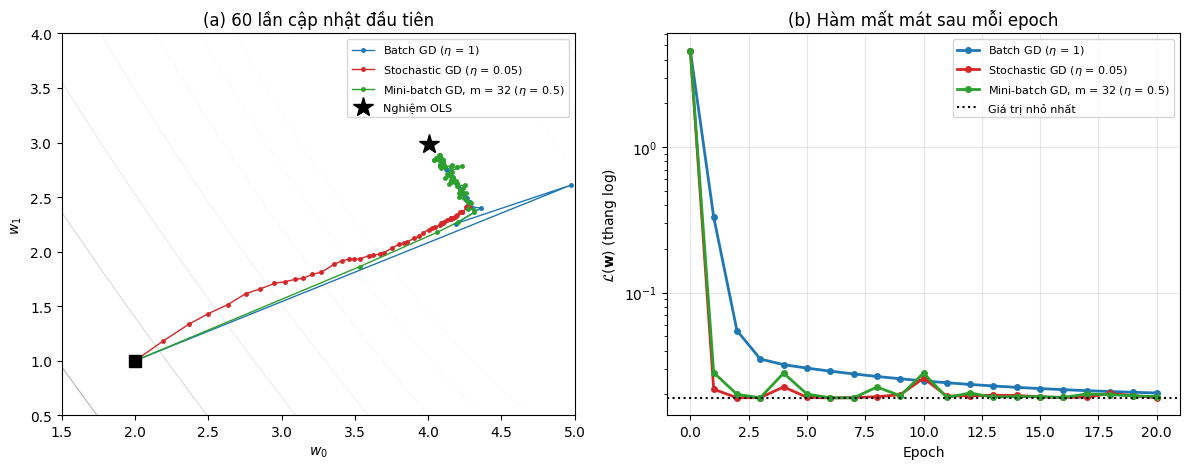

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].contour(W0, W1, L, levels=np.logspace(-1.6, 1.2, 15), cmap="Greys", linewidths=0.8)
for name, batch_size, eta, color in configs:
    w_history, losses = minibatch_gd(eta, batch_size, 20)
    first_steps = w_history[:61]
    axes[0].plot(first_steps[:, 0], first_steps[:, 1], "o-", color=color, ms=2.5, lw=1, label=name)
    axes[1].plot(losses, "o-", color=color, ms=4, lw=2, label=name)
axes[0].plot(2, 1, "ks", ms=8)
axes[0].plot(w_ols[0], w_ols[1], "*", color="black", ms=15, label="Nghiệm OLS")
axes[0].set_xlabel("$w_0$"); axes[0].set_ylabel("$w_1$")
axes[0].set_title("(a) 60 lần cập nhật đầu tiên")
axes[0].legend(fontsize=8, loc="upper right")
axes[1].axhline(cost(w_ols), color="black", ls=":", label="Giá trị nhỏ nhất")
axes[1].set_yscale("log"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel(r"$\mathcal{L}(\mathbf{w})$ (thang log)")
axes[1].set_title("(b) Hàm mất mát sau mỗi epoch")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "gd_variants.png", dpi=150)